# 18. Entanglement loops in Kitaev's spin liquid

**Goal.** Take one of the quantum spin liquids of Lyu, Chandorkar, Kapoor, Takei, Sørensen and Witczak-Krempa (*Multiparty entanglement loops in quantum spin liquids*, [arXiv:2505.18124](https://arxiv.org/abs/2505.18124); [Nat. Commun. 17, 5650 (2026)](https://doi.org/10.1038/s41467-026-71113-8)), find its ground state with DMRG on the very clusters the paper diagonalized exactly, and check the reduced density matrices (RDMs) and their multiparty entanglement against exact diagonalization (ED).

The paper's finding, in one line: in a spin liquid, small groups of neighbouring spins are *not* genuinely entangled with each other ("entanglement frustration"); genuine multiparty entanglement only appears in regions that contain a closed loop, like a hexagon of the honeycomb lattice.

**Which of the paper's models suit DMRG?** The paper studies several spin liquids, mostly with ED on periodic clusters of 24 to 36 spins. DMRG handles a model well when its couplings are short-ranged and real, it maps onto a cylinder without long bonds, its ground state is gapped (so the entanglement across a cut stays small), and it has symmetries a package can use.

| Model in the paper | What was computed there | For DMRG |
|---|---|---|
| **Kitaev honeycomb, no field** (Eq. 1 with $h = 0$): $\sum K_\gamma S^\gamma_i S^\gamma_j$, isotropic gapless spin liquid | ED on the 32-site Dyck and 24-site Nauru clusters; the exact Majorana solution of the infinite lattice (SM Tables II–IV); GMN of the hexagon, a "fork", pairs and triples (Fig. 3 at $h = 0$) | **Easy to medium.** Real, nearest-neighbour, spin 1/2, conserved fluxes that can be pinned; gapless, so the 24-site torus needs $\chi \approx 500$ and the 32-site one is out of reach (section 4); exact checks available. **This notebook.** |
| **Kitaev, anisotropic** ($K_z > K_x = K_y$), gapped $\mathbb Z_2$ (toric-code) spin liquid | exact Majorana solution, hexagon GMN against anisotropy (Fig. 4) | **Easy** on 24 sites. Gapped, little entanglement ($\chi = 128$ already gives the RDMs to $10^{-6}$); DMRG can sit in the wrong topological sector. **This notebook.** |
| Kitaev in a [111] field $h$ | ED on 32 and 24 sites, GMN of many regions against $h$ (Figs. 3, 7, 8) | **Medium to hard.** The field term $S^y$ makes $H$ complex and breaks flux conservation; the intermediate phase ($0.38 < h < 0.64$, Fig. 3) has competing states. ED here would need a complex solver. |
| Kitaev plus the three-spin term $\kappa S^xS^yS^z$ (the small-field effective model, SM Eq. 10) | exact Majorana solution (light curves in Fig. 3a) | Medium: complex three-site terms, but gapped, with an exact check. |
| Kagome Heisenberg $J_1$–$J_2$ (Eq. 2) | ED on 36 sites (12–36 in SM Fig. 14); GMN of the bowtie, hexagon, triangles (Fig. 5) | **Hard.** Frustrated, nearly degenerate competing orders, probably gapless (a Dirac spin liquid); the classic DMRG challenge needs cylinders of circumference 8–12. |
| Kagome with scalar chirality $\lambda\,\mathbf S_i\cdot(\mathbf S_j\times\mathbf S_k)$ (Eq. 3) | ED on 24 and 36 sites (Fig. 6) | Medium to hard: complex three-spin terms; the chiral phase is gapped but has chiral edge modes on cylinders. |
| RVB states (kagome, square lattice) | 36-site wavefunctions | Not a DMRG target: these are wavefunctions, not ground states of a simple Hamiltonian. |
| String nets (toric code, double semion, Fibonacci, ...) | exact RDMs, separability proofs (SM Sec. X) | The toric code is an exact small-$\chi$ MPS on a cylinder; the non-abelian nets have large local dimension and many-spin plaquette terms. Their RDMs are known exactly anyway. |

Kitaev's honeycomb model at zero field is the natural first step: a genuine spin liquid, a real Hamiltonian, and two exact references, ED on the paper's clusters and the exact solution of the infinite lattice.

In [1]:
import json
import logging
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import dmrg_from_scratch as dmrg
from dmrg_from_scratch import kitaev as kt
from dmrg_from_scratch.exact import ground_state, matvec_operator
from dmrg_from_scratch.microscopy import dense_rdm, partial_trace, pauli_expectations

logging.disable(logging.CRITICAL)
warnings.filterwarnings("ignore")
RES = json.loads(Path("../results/kitaev_loops.json").read_text())

## 1. One cluster, one call each

Kitaev's model on a small honeycomb torus of 16 spins: build the Hamiltonian, find the ground state with exact diagonalization and with this package's DMRG, and cut out the six spins of one hexagon. The model is $H = \sum_{\langle ij\rangle_\gamma} K_\gamma S_i^\gamma S_j^\gamma$ with $\mathbf S = \boldsymbol\sigma/2$ and $K_x = K_y = K_z = 1$ (antiferromagnetic), the convention of the paper's Eq. 1. The term $-0.2\sum_p W_p$ is explained in section 2; it does not change the ground state here, it only makes it unique.

In [2]:
H = kt.kitaev_honeycomb(4, 4, flux_penalty=0.2)          # 4 x 4 brick wall = 16-site honeycomb torus
E_ed, psi_ed = ground_state(H)
r = dmrg.dmrg(dmrg.pauli_string_mpo(H), chi_max=128, n_sweeps=6)
psi_dmrg = dmrg.to_dense(r["mps"])

hexagon = kt.hexagon(0, 0, 4, 4)                        # six sites around one hexagon
rho_ed, rho_dmrg = dense_rdm(psi_ed, hexagon, H.n), dense_rdm(psi_dmrg, hexagon, H.n)
print(f"energy: ED {E_ed:.12f}, DMRG {r['energy']:.12f}")
print(f"hexagon RDM, largest difference of an entry: {np.abs(rho_ed - rho_dmrg).max():.1e}")

energy: ED -4.836067977500, DMRG -4.836067977500
hexagon RDM, largest difference of an entry: 5.1e-15


The two RDMs agree to machine precision: at $\chi = 128$ this small torus is represented exactly. Now the entanglement. The genuine multiparty negativity (GMN; Jungnitsch, Moroder and Gühne, [arXiv:1010.6049](https://arxiv.org/abs/1010.6049)) is positive only if the parties are genuinely multipartite entangled; for two parties it is the negativity. Four regions, as in the paper's Fig. 3: the hexagon split into three pairs, a "fork" of six spins without a loop split the same way, two neighbours, and three consecutive spins.

In [3]:
fork = kt.fork(1, 1, 4, 4)
rho_fork = dense_rdm(psi_ed, fork, H.n)
pairs = [(0, 1), (2, 3), (4, 5)]
t0 = time.perf_counter()
print(f"hexagon, 3 pairs        GMN = {kt.region_measures(rho_ed.real, pairs):.4f}")
print(f"fork, 3 pairs           GMN = {kt.region_measures(rho_fork.real, pairs):.4f}")
print(f"two neighbours          negativity = {kt.region_measures(partial_trace(rho_ed, [0, 1]).real, [(0,), (1,)]):.4f}")
print(f"three consecutive spins GMN = {kt.region_measures(partial_trace(rho_ed, [0, 1, 2]).real, [(0,), (1,), (2,)]):.4f}")
print(f"({time.perf_counter() - t0:.0f} s)")
print(f"yet the two neighbours are strongly correlated: <Z1 Z2> = {np.real(pauli_expectations(rho_ed)['ZZIIII']):.3f}")

hexagon, 3 pairs        GMN = 0.2404


fork, 3 pairs           GMN = -0.0000
two neighbours          negativity = -0.0000
three consecutive spins GMN = -0.0000
(5 s)


yet the two neighbours are strongly correlated: <Z1 Z2> = -0.447


That is the paper's result in miniature. The hexagon is genuinely entangled; the fork, also six spins and also built from the same bonds, is not; neither is a pair nor a triple, even though neighbouring spins are strongly correlated. Entanglement sits on the loop.

The counterexample is any ordinary magnet: in the transverse-field Ising model, two neighbours are entangled at every field (notebook 17, and the paper's refs. 14 and 30).

## 2. The machinery: a honeycomb as a brick wall, fluxes, and degenerate ground states

**The lattice.** A honeycomb is a brick wall: put the sites on a grid, give every site its two horizontal neighbours and one vertical neighbour (up or down, alternating). In Kitaev's model the bond direction decides the coupling: horizontal bonds alternate between $S^xS^x$ and $S^yS^y$, vertical bonds are $S^zS^z$, so every spin has one bond of each type. Sites are numbered column by column, $s = xL_y + y$, the order the MPS walks through them. Wrapping the grid in both directions, with column $L_x$ glued to column 0 shifted by `twist` rows, gives a torus. The paper's two clusters are twisted brick walls: the 24-site Nauru graph is $6\times4$ with twist 2 and the 32-site Dyck graph is $4\times8$ with twist 4 (`tests/test_kitaev.py` checks both against the standard LCF notation of the two graphs).

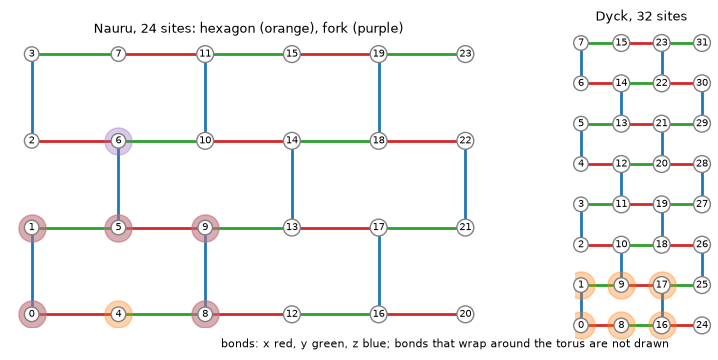

In [4]:
def draw(Lx, Ly, twist, regions, ax, title):
    colours = {"x": "tab:red", "y": "tab:green", "z": "tab:blue"}
    pos = {x * Ly + y: (x, y) for x in range(Lx) for y in range(Ly)}
    for i, j, g in kt.brickwall_bonds(Lx, Ly, True, twist):
        (x1, y1), (x2, y2) = pos[i], pos[j]
        if abs(x1 - x2) + abs(y1 - y2) == 1:  # bonds inside the drawing; the others wrap around the torus
            ax.plot([x1, x2], [y1, y2], color=colours[g], lw=2, zorder=1)
    for s, (x, y) in pos.items():
        ax.text(x, y, str(s), ha="center", va="center", fontsize=7, zorder=3,
                bbox=dict(boxstyle="circle,pad=0.25", fc="white", ec="0.5"))
    for sites, colour in regions:
        ax.scatter([pos[s][0] for s in sites], [pos[s][1] for s in sites], s=380, color=colour, alpha=0.35, zorder=2)
    ax.set_title(title, fontsize=9)
    ax.set_aspect("equal")
    ax.axis("off")


fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
Lx, Ly, tw = kt.NAURU
draw(Lx, Ly, tw, [(kt.hexagon(0, 0, Lx, Ly, tw), "tab:orange"), (kt.fork(1, 1, Lx, Ly, tw), "tab:purple")], ax[0],
     "Nauru, 24 sites: hexagon (orange), fork (purple)")
Lx, Ly, tw = kt.DYCK
draw(Lx, Ly, tw, [(kt.hexagon(0, 0, Lx, Ly, tw), "tab:orange")], ax[1], "Dyck, 32 sites")
fig.text(0.5, 0.02, "bonds: x red, y green, z blue; bonds that wrap around the torus are not drawn", ha="center", fontsize=8)
fig.tight_layout()

**Fluxes.** Around every hexagon $p$ the product $W_p = X_1Y_2Z_3X_4Y_5Z_6$ (on each site, the Pauli of the bond that leaves the hexagon) commutes with $H$ and with every other $W_q$ (Kitaev, [arXiv:cond-mat/0506438](https://arxiv.org/abs/cond-mat/0506438)). So the Hilbert space splits into flux sectors with $W_p = \pm1$, and in each sector the model is free Majorana fermions in a static $\mathbb Z_2$ gauge field: this is why it is exactly solvable. On the infinite lattice the ground state has $W_p = +1$ everywhere (Lieb's theorem, cited by Kitaev). On a small torus a sector with some $W_p = -1$ can be as low: on the 16-site torus it is exactly degenerate with the flux-free state. Adding $-\lambda\sum_p W_p$ leaves every eigenstate alone and lowers the flux-free sector. That is the `flux_penalty=0.2` above; in an MPO it needs six-spin terms, which `pauli_string_mpo` builds with one channel per term.

In [5]:
from scipy.sparse.linalg import eigsh

for lam in (0.0, 0.2):
    Hl = kt.kitaev_honeycomb(4, 4, flux_penalty=lam)
    vals, vecs = eigsh(matvec_operator(Hl), k=4, which="SA", tol=1e-12)
    order = np.argsort(vals)
    W = [np.real(pauli_expectations(dense_rdm(vecs[:, k], hexagon, Hl.n))["XYZXYZ"]) for k in order]
    print(f"lambda = {lam}: lowest energies {np.round(vals[order], 5)}, <W_p> on one hexagon {np.round(W, 3)}")

lambda = 0.0: lowest energies [-3.23607 -3.23607 -3.19823 -3.19823], <W_p> on one hexagon [ 0.064 -0.043  0.352 -0.549]


lambda = 0.2: lowest energies [-4.83607 -4.74626 -4.73578 -4.33205], <W_p> on one hexagon [1. 1. 1. 1.]


Without the penalty the lowest level is four-fold degenerate, and the eigenvectors the solver returns are arbitrary mixtures of flux sectors. With it the flux-free ground state is unique and every hexagon has $W_p = +1$.

**Topological sectors.** Even with every $W_p = +1$, a torus has more conserved quantities: loop operators built like $W_p$, but on a closed path that winds around the torus. On each site of the path, take the Pauli of the one bond the path does not use (Gohlke, Moessner and Pollmann, [arXiv:1804.06811](https://arxiv.org/abs/1804.06811); [PRB 98, 014418 (2018)](https://doi.org/10.1103/PhysRevB.98.014418), Sec. II, for the cylinder). A torus has two independent loops, one around each cycle. They commute with $H$, with every $W_p$ and with each other, so their eigenvalues $(W_{l_1}, W_{l_2}) = (\pm1, \pm1)$ split the flux-free states into four topological sectors (in the Majorana picture: periodic or antiperiodic fermions around each cycle). The same penalty trick picks one: `sector=(s1, s2)` adds $-\mu(s_1W_{l_1} + s_2W_{l_2})$ with $\mu = 0.5$, which lowers that sector by $2\mu$.

Here is why that matters for DMRG, in the gapped phase ($g = 1$, $K = (1/2, 1/2, 2)$) of the 16-site torus (under half a minute):

In [6]:
K = kt.anisotropic_couplings(1.0)
for l in kt.torus_loops(4, 4):
    print("loop operator:", " ".join(f"{p}{s}" for s, p in l))
H1 = kt.kitaev_honeycomb(4, 4, K=K, flux_penalty=0.2)
plain = dmrg.dmrg(dmrg.pauli_string_mpo(H1), chi_max=128, n_sweeps=6)["energy"]
print(f"plain DMRG {plain:.8f},   ED ground state {ground_state(H1)[0]:.8f}")
for sector in [(1, 1), (1, -1), (-1, 1), (-1, -1)]:
    Hs = kt.kitaev_honeycomb(4, 4, K=K, flux_penalty=0.2, sector=sector)
    e_ed = ground_state(Hs)[0] + 1.0                       # + 2 mu: the energy of H itself
    e_dmrg = dmrg.dmrg(dmrg.pauli_string_mpo(Hs), chi_max=128, n_sweeps=6)["energy"] + 1.0
    print(f"sector {sector}: ED {e_ed:.8f}, DMRG {e_dmrg:.8f}")

loop operator: Z0 Z4 Z8 Z12
loop operator: Y0 X1 Y4 X5 X6 Y7 X10 Y11


plain DMRG -5.72132034,   ED ground state -5.73577921


sector (1, 1): ED -5.73064859, DMRG -5.73064859


sector (1, -1): ED -5.72132034, DMRG -5.72132034


sector (-1, 1): ED -5.73577921, DMRG -5.73577921


sector (-1, -1): ED -5.71803399, DMRG -5.71803399


Plain DMRG is not slightly off: it found the *exact* ground state of the sector $(+1, -1)$, $0.014$ above the true ground state in $(-1, +1)$. In each sector separately, DMRG agrees with ED to machine precision.

The reason is the same as for any symmetry. The loops commute with $H$, and every step of DMRG is built from $H$ (the Lanczos update, TeNPy's mixer) or is an SVD, which keeps the sector structure. So once the sweeps have lost the amplitude of a sector, typically early on when truncation drops the more entangled one, no later step can bring it back: DMRG treats the sector like a conserved charge it does not know about. Starting from other random states does not help, nor does a larger $\chi$. Penalising every sector but one does.

The loops are not the only such quantities. Every term of $H$ flips spins in pairs, so the global parities $P_x = \prod_i X_i$ and $P_z = \prod_i Z_i$ are conserved too, and DMRG can lose a parity sector in the same way. On the Nauru cluster it does: one run in the right loop sector settled at $P_x = P_z = -1$, while every low state has $P_x = P_z = +1$. So the runs below scan all $4\times4 = 16$ sectors $(W_{l_1}, W_{l_2}, P_x, P_z)$, with `parity=(px, pz)` adding $-\mu(p_xP_x + p_zP_z)$.

**Degenerate ground states.** On the Nauru cluster the lowest level is three-fold degenerate in the isotropic model and two-fold in the gapped phase, each state in its own sector. The degenerate states are equally good ground states, but their RDMs differ, so "the RDM" has to be defined. The paper uses the $T\to0$ limit of the thermal state, the equal mixture over the degenerate manifold (its Methods). Here both methods use it: ED mixes every eigenvector within $10^{-6}$ of the lowest, and DMRG runs once per sector and mixes the sectors whose energies lie within $10^{-3}$ of the lowest. A sector is only as good as its convergence: if the most entangled sector is not converged, its energy is too high and it is left out.

**Which DMRG.** For the 24- and 32-site clusters the same MPOs go to TeNPy's DMRG ([arXiv:1805.00055](https://arxiv.org/abs/1805.00055); [SciPost Phys. Lect. Notes 5 (2018)](https://doi.org/10.21468/SciPostPhysLectNotes.5)): the algorithm of notebook 3, about four times faster (README, *How fast is it?*).

## 3. The paper's cluster: Nauru, 24 sites, DMRG against ED

Precomputed with `python scripts/make_results.py kitaev_loops` (about an hour on 12 cores; each ED of $2^{24}$ amplitudes takes about half an hour and 10 GB). Two points: the isotropic gapless spin liquid ($g = 0$) and the gapped $\mathbb Z_2$ phase ($g = 1$: $K_x = K_y = 1/2$, $K_z = 2$, on the anisotropy cut of the paper's Fig. 4, $K_{x,y} = 1 - g/2$, $K_z = 1 + g$).

In [7]:
nauru = {c["g"]: c for c in RES["clusters"] if c["n"] == 24}
for g, c in nauru.items():
    ed = c["ed"]
    print(f"g = {g}: ED ground level {ed['degeneracy']}-fold at E = {ed['energies'][0]:.8f},"
          f" sectors (W_l1, W_l2, P_x, P_z) {[tuple(s) for s in ed['sectors']]}")
    print(f"   DMRG keeps {[tuple(s) for s in c['dmrg_sectors']]}")
    for row in c["dmrg"]:
        low = sorted(zip(row["energies"], map(tuple, c["sectors"])))[:5]
        d = row["max_diff_ed"]
        print(f"   chi = {row['chi']:3d}: lowest sectors, E - E_ED: " + ", ".join(f"{s} {e - ed['energies'][0]:.1e}" for e, s in low))
        print(f"              max|rho_DMRG - rho_ED|: hexagon {d['hexagon']:.1e}, fork {d['fork']:.1e}   ({row['seconds']:.0f} s for 16 sectors)")

g = 0.0: ED ground level 3-fold at E = -7.16429836, sectors (W_l1, W_l2, P_x, P_z) [(-1, 1, 1, 1), (1, -1, 1, 1), (1, 1, 1, 1)]
   DMRG keeps [(1, 1, 1, 1), (1, -1, 1, 1), (-1, 1, 1, 1)]
   chi = 128: lowest sectors, E - E_ED: (1, 1, 1, 1) 4.5e-02, (-1, 1, 1, 1) 5.0e-02, (1, -1, 1, 1) 7.3e-02, (1, 1, -1, 1) 8.8e-01, (-1, 1, -1, 1) 8.8e-01
              max|rho_DMRG - rho_ED|: hexagon 2.0e-03, fork 1.9e-03   (703 s for 16 sectors)
   chi = 256: lowest sectors, E - E_ED: (1, 1, 1, 1) 2.4e-03, (-1, 1, 1, 1) 3.0e-03, (1, -1, 1, 1) 5.1e-03, (-1, 1, -1, 1) 8.5e-01, (1, 1, -1, 1) 8.5e-01
              max|rho_DMRG - rho_ED|: hexagon 1.4e-04, fork 1.7e-04   (2604 s for 16 sectors)
   chi = 512: lowest sectors, E - E_ED: (-1, 1, 1, 1) -3.6e-15, (1, 1, 1, 1) 1.8e-15, (1, -1, 1, 1) 6.2e-15, (-1, 1, -1, 1) 8.5e-01, (1, 1, -1, -1) 8.5e-01
              max|rho_DMRG - rho_ED|: hexagon 2.3e-13, fork 3.5e-13   (8658 s for 16 sectors)
g = 1.0: ED ground level 2-fold at E = -8.59982458, sectors (W_l1, W

In both phases DMRG finds exactly the sectors ED puts in the ground level, and with them the RDMs: to $10^{-13}$ at $\chi = 512$ in the gapless isotropic model, to $10^{-6}$ already at $\chi = 256$ in the gapped phase. The gapless state needs the larger $\chi$: its correlations decay slowly, while the gapped state's correlation length is short. On an infinite cylinder, the correlation length and the entanglement of the gapless sector keep growing with $\chi$ (Gohlke, Moessner and Pollmann, Sec. III A). Each sector run takes 11–16 minutes at $g = 0$ and 2–4 at $g = 1$.

So the GMNs agree to every printed digit. The loop result holds on 24 spins: in the isotropic model the hexagon is genuinely entangled and the fork, a pair and three spins are not. In the gapped phase the hexagon GMN drops, and the fork is entangled on these small tori (0.054 on 16 sites, 0.041 on 24); exercise 4 asks whether that survives in larger systems.

In [8]:
names = {"hexagon_3": "hexagon, 3 pairs", "hexagon_6": "hexagon, 6 spins", "fork_3": "fork, 3 pairs",
         "fork_6": "fork, 6 spins", "pair": "two neighbours", "three": "three consecutive"}
print(f"{'':20s}" + "".join(f"{'g = ' + str(g) + ': ED':>12s}{'DMRG':>9s}" for g in nauru))
for key, label in names.items():
    print(f"{label:20s}" + "".join(f"{nauru[g]['ed']['measures'][key]:12.4f}{nauru[g]['dmrg'][-1]['measures'][key]:9.4f}"
                                   for g in nauru))

                     g = 0.0: ED     DMRG g = 1.0: ED     DMRG
hexagon, 3 pairs          0.2080   0.2080      0.0696   0.0696
hexagon, 6 spins          0.0728   0.0728      0.0132   0.0132
fork, 3 pairs            -0.0000  -0.0000      0.0407   0.0407
fork, 6 spins            -0.0000  -0.0000     -0.0000  -0.0000
two neighbours           -0.0000  -0.0000     -0.0000  -0.0000
three consecutive        -0.0000  -0.0000     -0.0000  -0.0000


## 4. Beyond ED: the infinite lattice, and where DMRG fails

The infinite lattice is exact: the paper lists every nonzero correlation function of a hexagon in the Majorana solution (SM Tables II–IV), and $\rho = 2^{-6}\sum_P \langle P\rangle P$ rebuilds the hexagon RDM from them (`kt.exact_hexagon_rdm()`, to four digits).

In [9]:
rho_inf = kt.exact_hexagon_rdm().real
inf = RES["exact_infinite"]["measures"]
print(f"exact infinite-lattice hexagon: trace {np.trace(rho_inf):.4f}, smallest eigenvalue {np.linalg.eigvalsh(rho_inf).min():.1e}")
print(f"  two neighbours {kt.region_measures(partial_trace(rho_inf, [0, 1]), [(0,), (1,)]):.4f},"
      f" three consecutive {kt.region_measures(partial_trace(rho_inf, [0, 1, 2]), [(0,), (1,), (2,)]):.4f}")
print("hexagon GMN, 3 pairs / 6 spins, isotropic model (g = 0):")
print(f"   16-site torus, ED (live)   {kt.region_measures(rho_ed.real, pairs):.4f}")
print(f"   Nauru, 24, ED              {nauru[0.0]['ed']['measures']['hexagon_3']:.4f} / {nauru[0.0]['ed']['measures']['hexagon_6']:.4f}")
print(f"   Nauru, 24, DMRG            {nauru[0.0]['dmrg'][-1]['measures']['hexagon_3']:.4f} / {nauru[0.0]['dmrg'][-1]['measures']['hexagon_6']:.4f}")
print(f"   infinite lattice, exact    {kt.region_measures(rho_inf, pairs):.4f} (live) / {inf['hexagon_6']:.4f} (results/: about 100 s of MOSEK)")
print("   paper, Fig. 3a at h = 0 (Dyck, ED; read off the plot): about 0.20 / 0.065")

exact infinite-lattice hexagon: trace 1.0000, smallest eigenvalue -3.6e-17
  two neighbours -0.0000, three consecutive -0.0000
hexagon GMN, 3 pairs / 6 spins, isotropic model (g = 0):


   16-site torus, ED (live)   0.2404
   Nauru, 24, ED              0.2080 / 0.0728
   Nauru, 24, DMRG            0.2080 / 0.0728


   infinite lattice, exact    0.2045 (live) / 0.0653 (results/: about 100 s of MOSEK)
   paper, Fig. 3a at h = 0 (Dyck, ED; read off the plot): about 0.20 / 0.065


Already at 24 spins the hexagon GMN is within 0.004 (3 pairs) of the infinite lattice, and the regions without a loop are unentangled at every size.

**The 32-site Dyck cluster is a counterexample.** The paper's main cluster has $2^{32}$ amplitudes, beyond the ED of this package (the paper used a parallel Lanczos code), so DMRG would be the way in. With the same runs as for Nauru, it fails:

In [10]:
dyck = {c["g"]: c for c in RES["clusters"] if c["n"] == 32}
e_site = 1.5 * 0.25 * np.real(pauli_expectations(rho_inf)["ZZIIII"])   # 3/2 bonds per site, S = sigma/2, K = 1
print(f"infinite-lattice energy per site at g = 0: {e_site:.4f}  ->  estimate with the flux penalty:"
      f" Nauru {24 * e_site - 0.2 * 12:.3f} (ED {nauru[0.0]['ed']['energies'][0]:.3f}), Dyck {32 * e_site - 0.2 * 16:.3f}")
c = dyck[0.0]
for row in c["dmrg"]:
    worst = max(abs(w - s) for ws, sec in zip(row["loops"], c["sectors"]) for w, s in zip(ws, sec))
    print(f"Dyck g = 0, chi = {row['chi']:3d}: lowest energy {min(row['energies']):8.4f};"
          f" largest |measured loop - its sector| {worst:.2f}   ({row['seconds'] / 60:.0f} min for 4 sectors)")
m = c["dmrg"][-1]["measures"]
print(f"Dyck g = 0, chi = 512: hexagon GMN {m['hexagon_3']:.4f} / {m['hexagon_6']:.4f}, fork {m['fork_3']:.4f}"
      f"   (infinite lattice {inf['hexagon_3']:.4f} / {inf['hexagon_6']:.4f}; fork 0 in the paper's Fig. 3b)")

infinite-lattice energy per site at g = 0: -0.1968  ->  estimate with the flux penalty: Nauru -7.124 (ED -7.164), Dyck -9.499
Dyck g = 0, chi = 128: lowest energy  -7.2288; largest |measured loop - its sector| 0.66   (7 min for 4 sectors)
Dyck g = 0, chi = 256: lowest energy  -7.6413; largest |measured loop - its sector| 0.14   (40 min for 4 sectors)
Dyck g = 0, chi = 512: lowest energy  -8.0116; largest |measured loop - its sector| 0.12   (129 min for 4 sectors)
Dyck g = 0, chi = 512: hexagon GMN 0.2108 / 0.0564, fork -0.0000   (infinite lattice 0.2045 / 0.0653; fork 0 in the paper's Fig. 3b)


The energy still drops by about 0.4 with every doubling of $\chi$ and ends 1.5 above the infinite-lattice estimate. The estimate is good to 0.04 on Nauru, so that gap is not a finite-size effect. Even the sector labels are not pinned: a loop operator that should be $\pm1$ is measured as low as $0.88$ in magnitude. Yet the GMNs look reasonable: the fork is unentangled and the hexagon is close to the infinite lattice. That is the trap. An unconverged state can give plausible numbers, and only the energy against $\chi$ and the conserved quantities show that it is not the ground state.

Why 32 spins are so much harder than 24 is visible by counting. The entanglement an MPS can carry across a cut is at most $\log_2\chi$ bits, while a ground state of this model carries roughly a fixed amount per bond the cut crosses (the area law; Eisert, Cramer and Plenio, [arXiv:0808.3773](https://arxiv.org/abs/0808.3773); [Rev. Mod. Phys. 82, 277 (2010)](https://doi.org/10.1103/RevModPhys.82.277)). So the number to look at is the number of bonds crossing the worst cut of the site order:

In [11]:
def worst_cut(Lx, Ly, twist):
    bonds = kt.brickwall_bonds(Lx, Ly, True, twist)
    return max(sum((i < c) != (j < c) for i, j, _ in bonds) for c in range(1, Lx * Ly))


for name, cl in [("16-site torus", (4, 4, 0)), ("Nauru", kt.NAURU), ("Dyck", kt.DYCK)]:
    print(f"{name:14s} {cl[0] * cl[1]:2d} sites: worst cut crosses {worst_cut(*cl)} bonds")

16-site torus  16 sites: worst cut crosses 10 bonds
Nauru          24 sites: worst cut crosses 10 bonds
Dyck           32 sites: worst cut crosses 18 bonds


(The 16-site torus is so small that $\chi = 128$ already represents it exactly.) Every extra bond on the cut multiplies the $\chi$ needed by a constant factor. Nauru needs $\chi = 512$ for 10 bonds; at the same cost per bond, Dyck's 18 would need $512^{18/10} \approx 10^5$. A better site order helps only a little (the best found by a local search over swaps still crosses 12 bonds), and the Dyck graph has no narrower brick-wall layout. This is DMRG's real limit in two dimensions: the cost grows exponentially with the width of the system, not with its size.

## 5. Why this is a spin liquid, and what an entanglement loop is

A spin liquid is a magnet with no order, even at zero temperature. Here the absence of order is visible in the hexagon RDM: list every nonzero expectation value of a Pauli string on the six spins.

In [12]:
paulis = pauli_expectations(rho_ed.real)
for k, v in paulis.items():
    if abs(v) > 1e-8 and k != "IIIIII":
        print(f"{k}  {np.real(v):+.4f}")

IIIIXX  -0.5854
IIIZZI  -0.4472
IIYXYX  -0.2764
IIYYII  -0.5854
IIYYXX  +0.4663
IXXIII  -0.5854
IXXIXX  +0.3427
IXXZZI  +0.2618
XYXIIY  -0.2764
XYXZYZ  -0.5854
XYXZZY  +0.4663
XYZXYZ  +1.0000
XYZXZY  -0.5854
XYZYXZ  -0.4472
XZYXYZ  -0.5854
XZYXZY  +0.3427
XZYYXZ  +0.2618
YIIIIY  -0.5854
YIIZZY  +0.2618
YIYYIY  +0.3427
YXXIIY  +0.4663
YXXZYZ  +0.2618
YXXZZY  -0.3618
YXZXYZ  -0.4472
YXZXZY  +0.2618
YXZYXZ  +0.2000
ZYXZYX  +0.3427
ZYZXYX  -0.5854
ZYZYXX  +0.2618
ZZIIII  -0.4472
ZZIIXX  +0.2618
ZZIZZI  +0.2000
ZZYXYX  +0.4663
ZZYYII  +0.2618
ZZYYXX  -0.3618


No string with a single Pauli appears: $\langle\sigma^a_i\rangle = 0$ on every site. The only two-spin correlations are the six bonds of the hexagon, each in its own bond component ($ZZ$ on a $z$ bond, $XX$ on an $x$ bond, ...). Next come four-spin terms and, finally, the six-spin $\langle X_1Y_2Z_3X_4Y_5Z_6\rangle = \langle W_p\rangle = 1$.

The fluxes explain this list (Baskaran, Mandal and Shankar, [arXiv:cond-mat/0611547](https://arxiv.org/abs/cond-mat/0611547); [PRL 98, 247201 (2007)](https://doi.org/10.1103/PhysRevLett.98.247201)). Every site belongs to three hexagons, and each of them acts on it with a different Pauli: the Pauli of the one bond of the site that leaves that hexagon. So $\sigma^a_i$ commutes with one of the three $W_p$ and anticommutes with the other two: it flips two fluxes and takes a flux eigenstate to an orthogonal one, so $\langle\sigma^a_i\rangle = 0$. A product $\sigma^a_i\sigma^b_j$ survives only if it flips no flux, which happens only when $i$ and $j$ share an $a$ bond and $b = a$. Spin correlations therefore stop at nearest neighbours at any system size, even in the gapless isotropic model (the paper's SM Table II lists their values on the infinite lattice).

**What a loop is.** The six-spin correlation $\langle W_p\rangle = 1$ is perfect: the product of six Paulis around the hexagon is fixed, although no single spin is and only neighbouring pairs are correlated. Only a region that closes a loop contains such a term; the fork, open at its ends, does not. That is where the genuine six-party entanglement of section 1 comes from: the hexagon GMN is positive and the fork GMN is zero.

The paper (Sec. III) also finds that this entanglement survives measuring a single spin of the hexagon. Exercise 6 checks for which splittings of the five remaining spins into parties this holds.

## 6. What DMRG buys here

* **The paper's ED, reproduced, and a method that goes further.** On the 24-spin cluster DMRG gives the same ground level, sector by sector, and the same RDMs and GMNs as a Lanczos run on $2^{24}$ amplitudes. At this size it is not cheaper: 16 sector runs of 11–16 minutes against one ED of half an hour. What it buys is a method whose cost does not double with every added spin.
* **Each ground state on its own, with its labels.** ED returns an arbitrary basis of a degenerate level; here every state comes with its loop and parity eigenvalues, which is what the RDM of a single topological sector needs.
* **Length, not width.** The cost grows exponentially with the number of bonds a cut crosses and only linearly with the length. That is why the 32-site torus fails while long cylinders work: Gohlke, Moessner and Pollmann treat infinite cylinders of circumference 10 with $\chi$ up to 1600. A torus is the worst case, since every cut crosses the system twice.
* **Where ED stops anyway.** In a magnetic field the fluxes and loops are no longer conserved, so the sector trick goes, and the Majorana solution no longer applies. ED stops at a few dozen spins, so DMRG on cylinders is the tool there (Gohlke, Moessner and Pollmann; exercise 5).

## Exercises

1. **Fluxes.** Compute $\langle W_p\rangle$ for every hexagon of the 16-site ground state with `dense_rdm`. Then set `flux_penalty=-0.2`, which favours $W_p = -1$: what happens to the energy and to the hexagon GMN?
2. **Which sector does plain DMRG pick?** Run plain `dmrg` on the 16-site torus at $g = 1$ from several seeds (`seed=` in `dmrg.dmrg`), and measure both loop operators on the result with `dense_rdm` or `to_dense`. Is it always the same sector? Now start from the exact ground state plus a little noise: does DMRG stay there?
3. **A shorter loop.** On the $4\times4$ torus, a vertical loop around the torus has only four sites. Compute the GMN of those four spins as four parties and compare with the hexagon. Is the rule about hexagons, or about closed loops of bonds?
4. **The fork in the gapped phase.** On the 16-site torus at $g = 1$ the fork GMN is about 0.05. Is that a finite-size effect? Compare with the Nauru value in the results file (ED and DMRG agree there), then argue from the toric-code limit $K_z\to\infty$ what the fork RDM should become.
5. **Adding the field.** Add $-h\sum_i (S^x_i + S^y_i + S^z_i)/\sqrt3$ to the 16-site Hamiltonian with TeNPy (the $S^y$ term makes it complex; `pauli_string_mpo` is real only). Follow the hexagon and fork GMN up to $h = 1$ and compare with the paper's Fig. 3.
6. **Measuring one spin of the loop.** Project spin 1 of the exact infinite-lattice hexagon RDM onto $X = +1$, $Y = +1$ or $Z = +1$ and normalise. Compute the GMN of the remaining five spins with each spin as its own party, then for the three-party splits $(2)(34)(56)$ and $(23)(45)(6)$. Which splits stay genuinely entangled for each measurement? Compare with the 16-site torus.